*© Sabrine Bendimerad · [sbendimerad.github.io](https://sbendimerad.github.io) · Licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/): you may share and adapt this material with credit, for non-commercial use, under the same licence. Datasets keep their own licences.*

# Logistic regression with scikit-learn 📊

Let's come back to our customers dataset and change the objective: we would like to predict whether a person will buy a product (variable "Purchased") from the other variables. To do so, we'll train a logistic regression model and evaluate its performance.

## What will you learn in this course? 🧐🧐
This lesson is a follow-along demo: it guides you through the steps of building logistic regression models and evaluating them on real data.

* Multivariate logistic regression
    * Training Pipeline
    * Test Pipeline

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import  OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"


In [ ]:
# Import dataset
print("Loading dataset...")
dataset = pd.read_csv("data/customers.csv")
print("...Done.")
print()

Loading dataset...
...Done.



In [ ]:
# Basic stats
print("Number of rows : {}".format(dataset.shape[0]))
print()

print("Display of dataset: ")
display(dataset.head())
print()

print("Basics statistics: ")
data_desc = dataset.describe(include='all')
display(data_desc)
print()

print("Percentage of missing values: ")
display(100*dataset.isnull().sum()/dataset.shape[0])


Number of rows : 400

Display of dataset: 


,Country,Age,Salary,Purchased
0,Germany,20.0,38500.0,No
1,Spain,33.0,32200.0,No
2,Italy,43.0,47900.0,No
3,Germany,62.0,54300.0,No
4,France,53.0,51800.0,Yes



Basics statistics: 


,Country,Age,Salary,Purchased
count,400,391.000000,400.000000,400
unique,4,NaN,NaN,2
top,France,NaN,NaN,No
freq,139,NaN,NaN,241
mean,NaN,42.437340,47013.500000,NaN
std,NaN,13.297408,14079.992301,NaN
min,NaN,20.000000,13000.000000,NaN
25%,NaN,31.000000,35800.000000,NaN
50%,NaN,43.000000,47250.000000,NaN
75%,NaN,54.000000,58150.000000,NaN



Percentage of missing values: 


Country      0.00
Age          2.25
Salary       0.00
Purchased    0.00
dtype: float64

## EDA
The EDA done in the previous lessons is still valid. As we now want to predict _Purchased_ from the other variables, it is also interesting to display the distribution of the explanatory variables for each value of _Purchased_:

In [ ]:
# Univariate analysis
# Distribution of each numeric variable
num_features = ['Age', 'Salary']
for f in num_features:
    fig = px.histogram(dataset, f, color = 'Purchased', facet_row = 'Purchased', histnorm = 'probability')
    fig.show()

:::tip Good to know
As the target variable (_Purchased_) is categorical, we can't make a scatterplot or compute a correlation coefficient to check the dependency between the features and the target. The figure above gives a hint about which features carry useful information to predict Y: if a variable's distribution is very different depending on the value of Y, this variable might be a good predictor of the target!
:::

## Baseline model: simple logistic regression
Let's try a first basic model: a simple logistic regression with only one feature (_Salary_).

In [ ]:
# Separate target variable Y from features X
print("Separating labels from features...")
features_list = ["Salary"]
target_variable = "Purchased"

X = dataset.loc[:,features_list]
Y = dataset.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

Separating labels from features...
...Done.

Y : 
0     No
1     No
2     No
3     No
4    Yes
Name: Purchased, dtype: str

X :
    Salary
0  38500.0
1  32200.0
2  47900.0
3  54300.0
4  51800.0


In [ ]:
# Divide dataset Train set & Test set 
print("Dividing into train and test sets...")
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



### Preprocessing
:::note Simplified syntax
In this first example, we don't need to use the classes `Pipeline` and `ColumnTransformer` because the preprocessing of the features X is very simple: we just standardize the variable _Salary_ (there are no missing values in this column). So we can simply create an instance of `StandardScaler` and call its `fit_transform` and `transform` methods directly, passing X_train/X_test as arguments.

We'll also apply label encoding to the target Y_train/Y_test, because it's categorical this time 🤓
:::

In [ ]:
print("Preprocessing X_train...")
print(X_train.head())
print()
preprocessor = StandardScaler()
X_train = preprocessor.fit_transform(X_train)
print("...Done!")
print(X_train[0:5,:]) # X_train is now a numpy array
print() 

# Label encoding
print("Encoding labels...")
print(Y_train.head())
encoder = LabelEncoder()
Y_train = encoder.fit_transform(Y_train)
print("...Done")
print(Y_train[0:5])

Preprocessing X_train...
      Salary
336  55000.0
64   69400.0
55   63700.0
106  35100.0
300  49500.0

...Done!
[[ 0.56025614]
 [ 1.57318833]
 [ 1.172236  ]
 [-0.83955988]
 [ 0.17337231]]

Encoding labels...
336    Yes
64     Yes
55      No
106     No
300     No
Name: Purchased, dtype: str
...Done
[1 1 0 0 0]


In [ ]:
# Test pipeline
print("Preprocessing X_test...")
print(X_test.head())
print()
X_test = preprocessor.transform(X_test)
print("...Done!")
print(X_test[0:5,:]) # X_test is now a numpy array
print() 

# Label encoding
print("Encoding labels...")
print(Y_test.head())
Y_test = encoder.transform(Y_test)
print("...Done")
print(Y_test[0:5])

Preprocessing X_test...
      Salary
132  35800.0
309  38300.0
341  46700.0
196  51700.0
246  28200.0

...Done!
[[-0.79032012]
 [-0.61446384]
 [-0.02358672]
 [ 0.32812584]
 [-1.32492322]]

Encoding labels...
132    No
309    No
341    No
196    No
246    No
Name: Purchased, dtype: str
...Done
[0 0 0 0 0]


### Train model

In [ ]:
# Train model
print("Train model...")
classifier = LogisticRegression()
classifier.fit(X_train, Y_train)
print("...Done.")

Train model...
...Done.


### Performance assessment

In [ ]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = classifier.predict(X_train)
print("...Done.")
print(Y_train_pred)
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on training set...")
Y_train_proba = classifier.predict_proba(X_train)
print("...Done.")
print(Y_train_proba)
print()

Predictions on training set...
...Done.
[1 1 1 0 0 0 0 0 0 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 0 1 1 1 0 0 0 0 1 0 0 0 0
 0 0 1 0 1 0 1 0 1 0 0 0 1 0 1 1 1 0 0 0 1 1 0 1 0 0 0 1 1 0 0 1 0 0 1 0 0
 1 0 0 0 1 0 1 1 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 0 0 1 1 0 0 1 0 0 0 1 0 0 1
 1 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1 0 0 1 1 1 0 1 0 1 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0 0 1 1 0 0
 1 1 1 1 1 0 0 0 0 0 0 0 1 0 0 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 0 1 0 0 1 1
 0 0 0 0 1 1 0 0 0 0 0 1 0 1 0 1 0 1 1 1 0 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1
 1 1 1 0 1 0 0 1 0 0 1 1 0 0 1 0 0 0 0 1 0 1 1 0 1 0 1 1 1 0 0 0 0 1 0 1 0
 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0]

Probabilities on training set...
...Done.
[[0.38869884 0.61130116]
 [0.07066583 0.92933417]
 [0.14983872 0.85016128]
 [0.92287598 0.07712402]
 [0.58864307 0.41135693]
 [0.81886963 0.18113037]
 [0.71177843 0.28822157]
 [0.97893603 0.02106397]
 [0.59220947 0.40779053]
 [0.13891213 0.86108787]
 [0.23854157 0.76

In [ ]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = classifier.predict(X_test)
print("...Done.")
print(Y_test_pred)
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on test set...")
Y_test_proba = classifier.predict_proba(X_test)
print("...Done.")
print(Y_test_proba)
print()

Predictions on test set...
...Done.
[0 0 0 0 0 1 1 1 0 0 0 0 1 1 1 1 0 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 1 0 0
 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 1 0 1 1 0 0 1 0 0
 0 1 0 0 1 1]

Probabilities on test set...
...Done.
[[0.91519974 0.08480026]
 [0.88185782 0.11814218]
 [0.68380303 0.31619697]
 [0.50847451 0.49152549]
 [0.97067914 0.02932086]
 [0.14611997 0.85388003]
 [0.24667077 0.75332923]
 [0.06597381 0.93402619]
 [0.9117023  0.0882977 ]
 [0.75768077 0.24231923]
 [0.9806854  0.0193146 ]
 [0.75768077 0.24231923]
 [0.13715741 0.86284259]
 [0.20307828 0.79692172]
 [0.0788176  0.9211824 ]
 [0.2254066  0.7745934 ]
 [0.67739118 0.32260882]
 [0.42426134 0.57573866]
 [0.0697034  0.9302966 ]
 [0.78621087 0.21378913]
 [0.8878668  0.1121332 ]
 [0.74388614 0.25611386]
 [0.89500106 0.10499894]
 [0.86560685 0.13439315]
 [0.95045306 0.04954694]
 [0.96850596 0.03149404]
 [0.69329065 0.30670935]
 [0.03662663 0.96337337]
 [0.18688161 0.81311839]
 [0.90041703 0.09958297]
 [0.7683465

In [ ]:
# Print scores
print("accuracy on training set : ", accuracy_score(Y_train, Y_train_pred))
print("accuracy on test set : ", accuracy_score(Y_test, Y_test_pred))
print()

print("f1-score on training set : ", f1_score(Y_train, Y_train_pred))
print("f1-score on test set : ", f1_score(Y_test, Y_test_pred))
print()

accuracy on training set :  0.821875
accuracy on test set :  0.8125

f1-score on training set :  0.7816091954022989
f1-score on test set :  0.7368421052631579



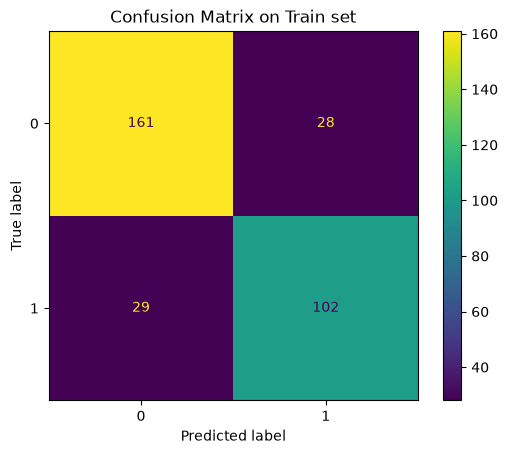

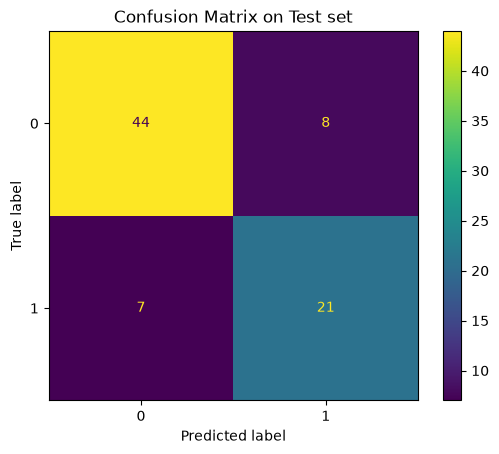

In [ ]:
# Visualize confusion matrices
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Train set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(classifier, X_train, Y_train, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Test set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(classifier, X_test, Y_test, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

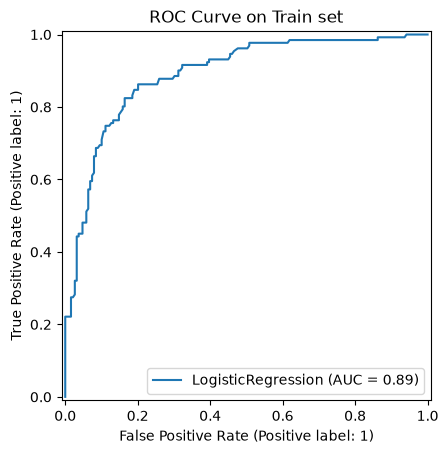

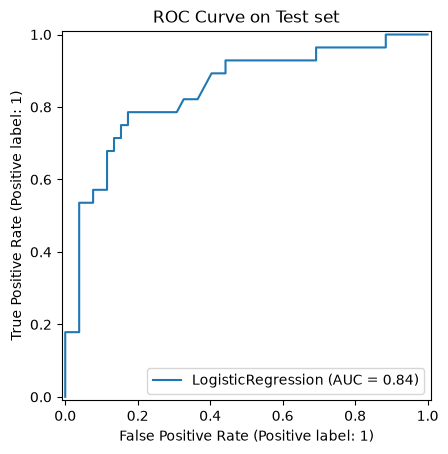

In [ ]:
# Visualize ROC curves
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Train set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(classifier, X_train, Y_train, ax=ax) # RocCurveDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Test set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(classifier, X_test, Y_test, ax=ax) # RocCurveDisplay from sklearn
plt.show()

In [ ]:
# Visualize the model
# Visualize predictions on training Set
fig = px.scatter(x = X_train.flatten().tolist(), y = Y_train, title = "training set")
fig.add_trace(go.Scatter(x = X_train.flatten().tolist(), y = Y_train_pred, name = "predictions"))
fig.add_trace(go.Scatter(x = X_train.flatten().tolist(), y = Y_train_proba[:,1], name = "probabilities"))
fig.show()

In [ ]:
# Visualize predictions on test Set
fig = px.scatter(x = X_test.flatten().tolist(), y = Y_test, title = "test set")
fig.add_trace(go.Scatter(x = X_test.flatten().tolist(), y = Y_test_pred, name = "predictions"))
fig.add_trace(go.Scatter(x = X_test.flatten().tolist(), y = Y_test_proba[:,1], name = "probabilites"))
fig.show()

## Multivariate logistic regression
Let's train a multivariate model with 3 variables: `Age`, `Country` and `Salary`.

In [ ]:
# Separate target variable Y from features X
print("Separating labels from features...")
target_variable = "Purchased"

X = dataset.drop(target_variable, axis = 1)
Y = dataset.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

Separating labels from features...
...Done.

Y : 
0     No
1     No
2     No
3     No
4    Yes
Name: Purchased, dtype: str

X :
   Country   Age   Salary
0  Germany  20.0  38500.0
1    Spain  33.0  32200.0
2    Italy  43.0  47900.0
3  Germany  62.0  54300.0
4   France  53.0  51800.0


In [ ]:
# Automatically detect names of numeric/categorical columns
numeric_features = []
categorical_features = []
for i,t in X.dtypes.items():
    if ('float' in str(t)) or ('int' in str(t)) :
        numeric_features.append(i)
    else :
        categorical_features.append(i)

print('Found numeric features ', numeric_features)
print('Found categorical features ', categorical_features)

Found numeric features  ['Age', 'Salary']
Found categorical features  ['Country']


In [ ]:
# Divide dataset Train set & Test set 
print("Dividing into train and test sets...")
# WARNING : don't forget stratify=Y for classification problems
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify = Y)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



### Preprocessing

In [ ]:
# Create pipeline for numeric features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')), # missing values will be replaced by columns' mean
    ('scaler', StandardScaler())
])

In [ ]:
# Create pipeline for categorical features
categorical_transformer = OneHotEncoder(drop='first') # no missing values in categorical data, so we only need the OHE

In [ ]:
# Use ColumnTransformer to make a preprocessor object that describes all the treatments to be done
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [ ]:
# Preprocessings on train set
print("Performing preprocessings on train set...")
print(X_train.head())
X_train = preprocessor.fit_transform(X_train)
print('...Done.')
print(X_train[0:5]) # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()
# Label encoding
print("Encoding labels...")
print(Y_train.head())
encoder = LabelEncoder()
Y_train = encoder.fit_transform(Y_train)
print("...Done")
print(Y_train[0:5])

# Preprocessings on test set
print("Performing preprocessings on test set...")
print(X_test.head()) 
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
print(X_test[0:5,:]) # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore
print()
# Label encoding
print("Encoding labels...")
print(Y_test[0:5])
Y_test = encoder.transform(Y_test)
print("...Done")
print(Y_test[0:5])

Performing preprocessings on train set...
     Country   Age   Salary
76    France  44.0  44000.0
367  Germany  38.0  48900.0
255  Germany  65.0  64700.0
218    Italy  21.0  25200.0
195   France  48.0  55700.0
...Done.
[[ 0.10554507 -0.23953466  0.          0.          0.        ]
 [-0.34803305  0.10714279  1.          0.          0.        ]
 [ 1.69306849  1.2250007   1.          0.          0.        ]
 [-1.63317106 -1.56964408  0.          1.          0.        ]
 [ 0.40793048  0.5882462   0.          0.          0.        ]]

Encoding labels...
76      No
367     No
255    Yes
218     No
195    Yes
Name: Purchased, dtype: str
...Done
[0 0 1 0 1]
Performing preprocessings on test set...
     Country   Age   Salary
357  Germany  59.0  68000.0
228  Germany  46.0  61000.0
105  Germany  52.0  67300.0
115    Italy  41.0  49600.0
188  Germany  31.0  30200.0
...Done.
[[ 1.23949037  1.45847736  1.          0.          0.        ]
 [ 0.25673778  0.96322385  1.          0.          0.        

### Train model

In [ ]:
# Train model
print("Train model...")
classifier = LogisticRegression()
classifier.fit(X_train, Y_train)
print("...Done.")

Train model...
...Done.


### Performance assessment

In [ ]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = classifier.predict(X_train)
print("...Done.")
print(Y_train_pred)
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on training set...")
Y_train_proba = classifier.predict_proba(X_train)
print("...Done.")
print(Y_train_proba)
print()

Predictions on training set...
...Done.
[0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 1 1 1 0 1 1 0 0 1 1 1 1 0
 0 0 0 0 1 0 1 1 0 1 1 1 0 1 0 0 0 0 0 0 0 0 1 1 1 1 0 1 0 1 1 0 0 0 1 1 0
 0 0 0 0 1 1 1 0 0 0 1 0 0 0 1 0 0 1 1 1 1 0 0 0 0 0 1 0 1 1 1 1 0 0 0 0 0
 1 0 1 0 0 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 1 1 0 0 1 0 0 1 0 0
 0 1 0 0 0 1 0 0 1 0 1 0 0 1 0 0 1 0 1 0 1 0 0 1 1 0 1 1 0 0 0 0 1 1 0 1 0
 0 0 1 0 1 1 0 1 0 0 1 0 1 1 0 0 1 0 0 1 0 1 0 1 1 1 0 1 0 1 1 0 0 1 0 1 0
 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 1 1
 0 0 0 1 0 0 1 0 0 0 0 1 1 1 1 1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 1 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 0]

Probabilities on training set...
...Done.
[[0.70418094 0.29581906]
 [0.78620097 0.21379903]
 [0.09434605 0.90565395]
 [0.98667073 0.01332927]
 [0.39313269 0.60686731]
 [0.888697   0.111303  ]
 [0.84125487 0.15874513]
 [0.39887102 0.60112898]
 [0.85860954 0.14139046]
 [0.94459133 0.05540867]
 [0.96000925 0.03

In [ ]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = classifier.predict(X_test)
print("...Done.")
print(Y_test_pred)
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on test set...")
Y_test_proba = classifier.predict_proba(X_test)
print("...Done.")
print(Y_test_proba)
print()

Predictions on test set...
...Done.
[1 1 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 1 1 0 1 1 0 0 1 0 0 0 0
 0 0 0 1 1 0 1 0 0 1 1 0 1 0 1 0 1 1 0 0 1 0 1 1 0 0 1 0 1 1 0 1 0 0 0 0 0
 1 0 0 0 0 1]

Probabilities on test set...
...Done.
[[0.115822   0.884178  ]
 [0.40929829 0.59070171]
 [0.19951684 0.80048316]
 [0.64913161 0.35086839]
 [0.96872083 0.03127917]
 [0.96239997 0.03760003]
 [0.31120689 0.68879311]
 [0.93158969 0.06841031]
 [0.37441821 0.62558179]
 [0.97590252 0.02409748]
 [0.77611083 0.22388917]
 [0.7413634  0.2586366 ]
 [0.97886506 0.02113494]
 [0.53860846 0.46139154]
 [0.66179098 0.33820902]
 [0.99567389 0.00432611]
 [0.64463973 0.35536027]
 [0.41277331 0.58722669]
 [0.95431071 0.04568929]
 [0.95158415 0.04841585]
 [0.14613992 0.85386008]
 [0.72478069 0.27521931]
 [0.48345257 0.51654743]
 [0.91149801 0.08850199]
 [0.92413953 0.07586047]
 [0.3755356  0.6244644 ]
 [0.04579373 0.95420627]
 [0.55339892 0.44660108]
 [0.10459826 0.89540174]
 [0.21512962 0.78487038]
 [0.9766231

In [ ]:
# Print scores
print("accuracy on training set : ", accuracy_score(Y_train, Y_train_pred))
print("accuracy on test set : ", accuracy_score(Y_test, Y_test_pred))
print()

print("f1-score on training set : ", f1_score(Y_train, Y_train_pred))
print("f1-score on test set : ", f1_score(Y_test, Y_test_pred))
print()

accuracy on training set :  0.83125
accuracy on test set :  0.8125

f1-score on training set :  0.784
f1-score on test set :  0.7619047619047619



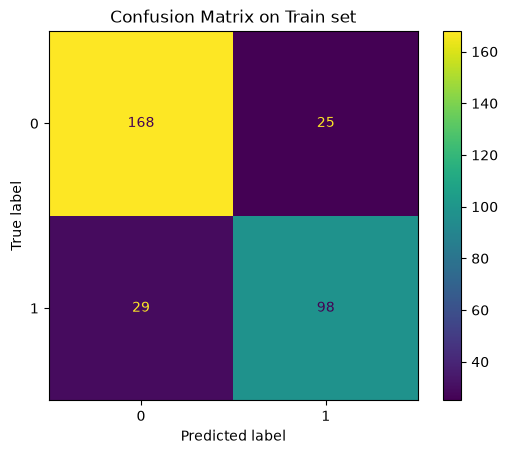

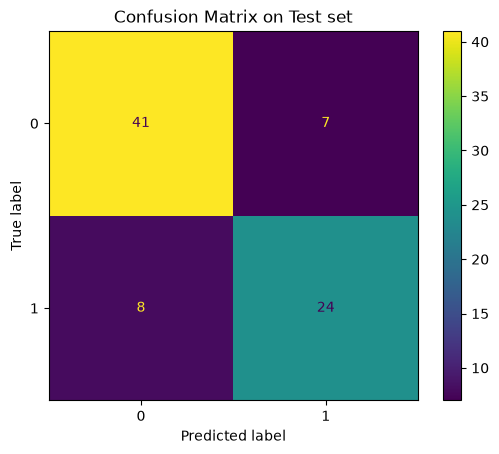

In [ ]:
# Visualize confusion matrices
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Train set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(classifier, X_train, Y_train, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Test set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(classifier, X_test, Y_test, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

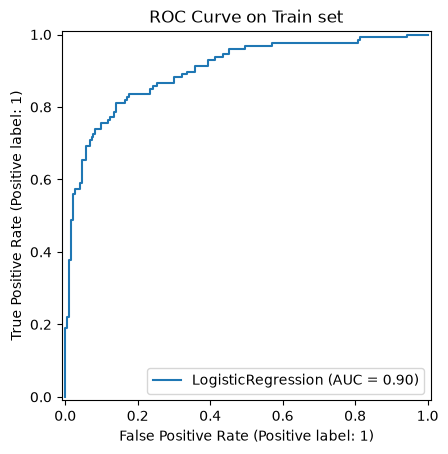

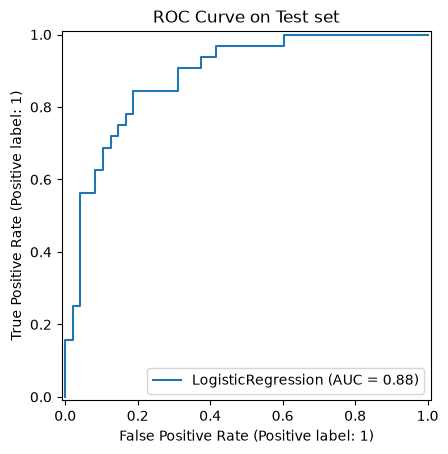

In [ ]:
# Visualize ROC curves
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Train set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(classifier, X_train, Y_train, ax=ax) # RocCurveDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Test set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(classifier, X_test, Y_test, ax=ax) # RocCurveDisplay from sklearn
plt.show()

## Resources 📚📚

* Metrics and scoring: quantifying the quality of predictions - [https://scikit-learn.org/stable/modules/model_evaluation.html](https://scikit-learn.org/stable/modules/model_evaluation.html#confusion-matrix)
* ConfusionMatrixDisplay - [https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay.from_estimator)
* RocCurveDisplay - [https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions)